In [17]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.templates.default = "plotly_white"
pio.renderers.default = "vscode+png"

from src.database import engine
import kaleido

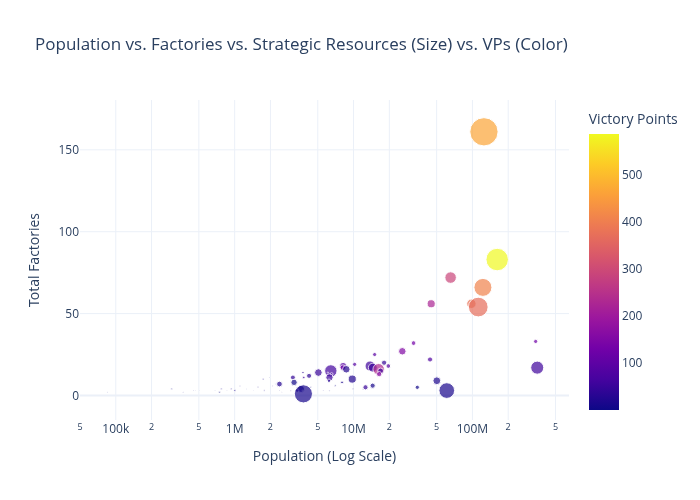

In [18]:
query = """
SELECT 
    c.country_name,
    c.country_tag,
    COUNT(s.state_id) AS total_states,
    SUM(s.population) AS total_population,
    SUM(s.victory_points) AS total_vps,
    SUM(s.civilian_factories) AS total_civs,
    SUM(s.military_factories) AS total_mils,
    SUM(s.naval_factories) AS total_navals,
    SUM(s.total_factories) AS total_factories,
    SUM(s.base_oil) AS total_oil,
    SUM(s.base_aluminum) AS total_aluminum,
    SUM(s.base_rubber) AS total_rubber,
    SUM(s.base_tungsten) AS total_tungsten,
    SUM(s.base_steel) AS total_steel,
    SUM(s.base_chromium) AS total_chromium,
    SUM(s.total_base_resources) AS aggregate_resources
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_factories DESC;
"""

df_country = pd.read_sql(query, engine)

fig_bubble = px.scatter(
    df_country.head(84),
    x ="total_population",
    y ="total_factories",
    size="aggregate_resources",
    color="total_vps",
    hover_name="country_name",
    log_x=True,
    title="Population vs. Factories vs. Strategic Resources (Size) vs. VPs (Color)",
    labels={
        "total_population": "Population (Log Scale)",
        "total_factories": "Total Factories",
        "total_resources": "Total Resources",
        "total_vps": "Victory Points"
    },
    template="plotly_white"
)
fig_bubble.show()

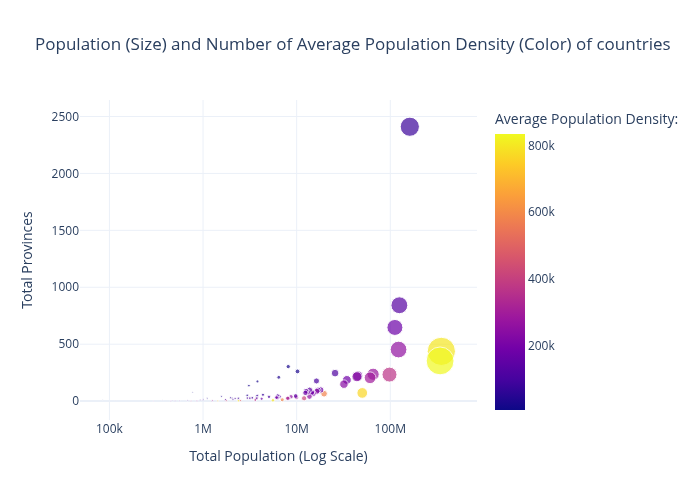

In [19]:
query_population = """
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.provinces_count) AS total_provinces,
    SUM(s.population) AS total_population,
    ROUND(AVG(s.population_density))::INT AS avg_population_density
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_population DESC;
"""

df_country = pd.read_sql(query_population, engine)

fig_bubble = px.scatter(
    df_country.head(84),
    x="total_population",
    y="total_provinces",
    size="total_population",
    color="avg_population_density",
    hover_name="country_name",
    log_x=True,
    title="Population (Size) and Number of Average Population Density (Color) of countries",
    labels={
        "total_population": "Total Population (Log Scale)",
        "total_provinces": "Total Provinces",
        "avg_population_density": "Average Population Density: "
    },
    template="plotly_white"
)
fig_bubble.show()

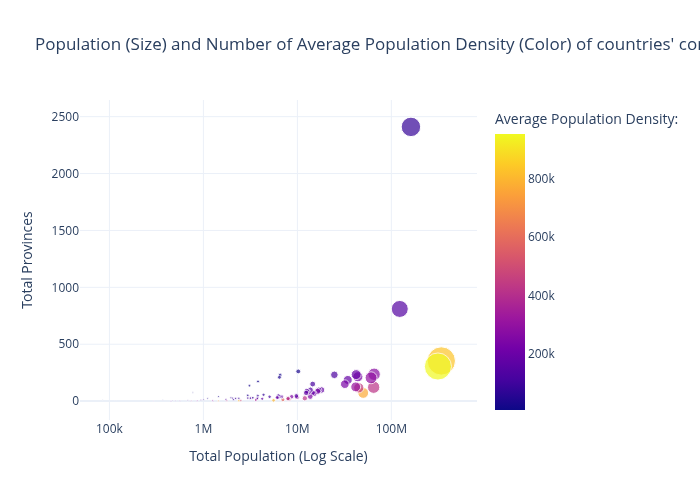

In [20]:
query_core_population = """
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.provinces_count) AS total_provinces,
    SUM(s.population) AS total_population,
    ROUND(AVG(s.population_density))::INT AS avg_population_density
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE state_status = 'Core'
GROUP BY c.country_name, c.country_tag
ORDER BY total_population DESC;
"""

df_core_pop = pd.read_sql(query_core_population, engine)

fig_bubble = px.scatter(
    df_core_pop.head(84),
    x="total_population",
    y="total_provinces",
    size="total_population",
    color="avg_population_density",
    hover_name="country_name",
    log_x=True,
    title="Population (Size) and Number of Average Population Density (Color) of countries' cores",
    labels={
        "total_population": "Total Population (Log Scale)",
        "total_provinces": "Total Provinces",
        "avg_population_density": "Average Population Density: "
    },
    template="plotly_white"
)
fig_bubble.show()

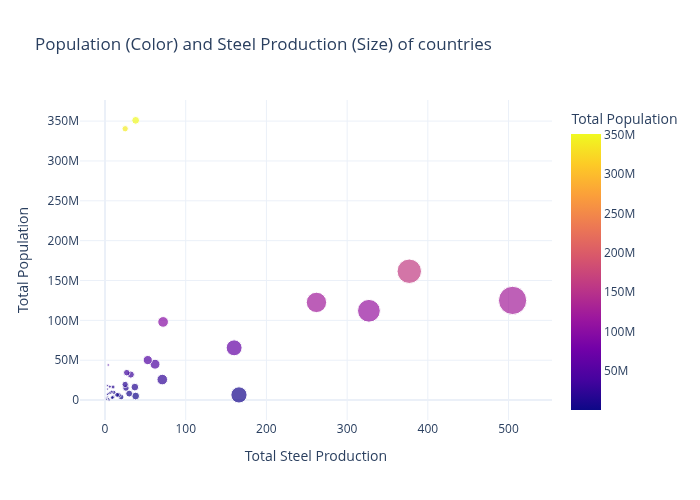

In [21]:
query_steel="""
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.base_steel) AS total_steel,
    SUM(s.population) AS total_population
FROM fact_state_1_14_5 s 
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
HAVING SUM(s.base_steel) > 0
ORDER BY total_steel DESC;
"""
df_steel = pd.read_sql(query_steel, engine)

fig_bubble = px.scatter(
    df_steel.head(84),
    x="total_steel",
    y="total_population",
    size="total_steel",
    color="total_population",
    hover_name="country_name",
    title="Population (Color) and Steel Production (Size) of countries",
    labels={
        "total_steel": "Total Steel Production",
        "total_population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()


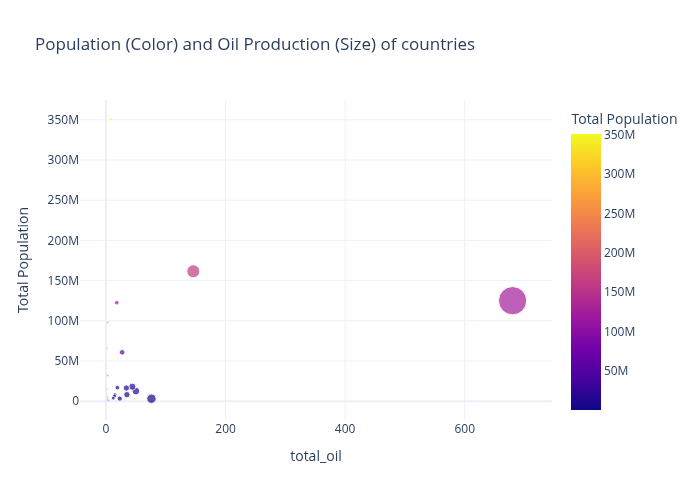

In [22]:
query_oil="""
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.base_oil) AS total_oil,
    SUM(s.population) AS total_population
FROM fact_state_1_14_5 s 
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
HAVING SUM(s.base_oil) > 0
ORDER BY total_oil DESC;
"""

df_oil = pd.read_sql(query_oil, engine)

fig_bubble = px.scatter(
    df_oil.head(84),
    x="total_oil",
    y="total_population",
    size="total_oil",
    color="total_population",
    hover_name="country_name",
    title="Population (Color) and Oil Production (Size) of countries",
    labels={
        "total_steel": "Total Oil Production",
        "total_population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()

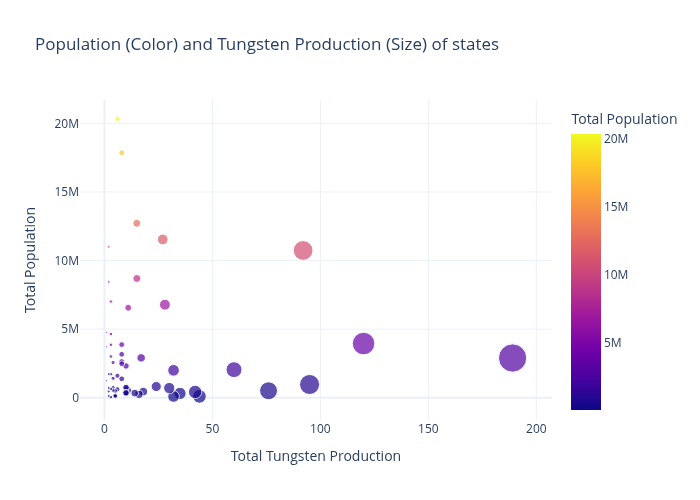

In [23]:
query_top_tungsten_states = """
SELECT 
    s.state_name,
    c.country_name AS owner_country,
    s.population, 
    s.base_tungsten
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE s.base_tungsten > 0
ORDER BY s.base_tungsten DESC;
"""

df_state_tungsten = pd.read_sql(query_top_tungsten_states, engine)
fig_bubble = px.scatter(
    df_state_tungsten.head(969),
    x="base_tungsten",
    y="population",
    size="base_tungsten",
    color="population",
    hover_name="state_name",
    hover_data={"owner_country": True, "base_tungsten": True, "population": True},
    title="Population (Color) and Tungsten Production (Size) of states",
    labels={
        "owner_country": "Owner Country",
        "base_tungsten": "Total Tungsten Production",
        "population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()

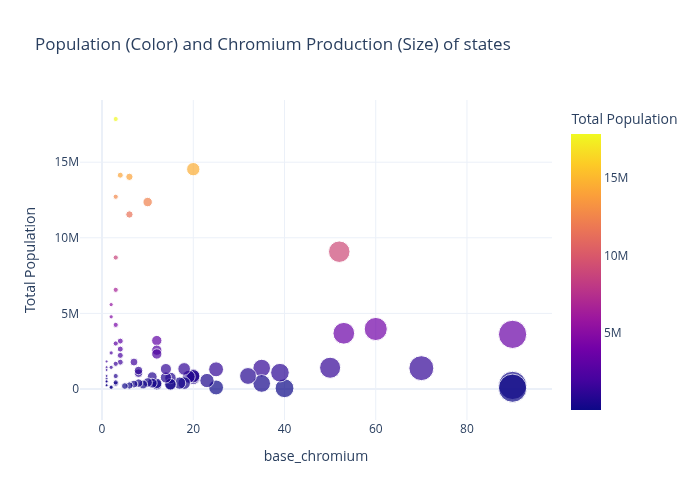

In [24]:
query_top_chromium_states = """
SELECT 
    s.state_name,
    c.country_name AS owner_country,
    s.population,
    s.base_chromium 
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE s.base_chromium > 0
ORDER BY s.base_chromium DESC;
"""

df_state_chromium = pd.read_sql(query_top_chromium_states, engine)
fig_bubble = px.scatter(
    df_state_chromium.head(969),
    x="base_chromium",
    y="population",
    size="base_chromium",
    color="population",
    hover_name="state_name",
    hover_data={"owner_country": True, "base_chromium": True, "population": True},
    title="Population (Color) and Chromium Production (Size) of states",
    labels={
        "owner_country": "Owner Country",
        "base_tungsten": "Total Chromium Production",
        "population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()

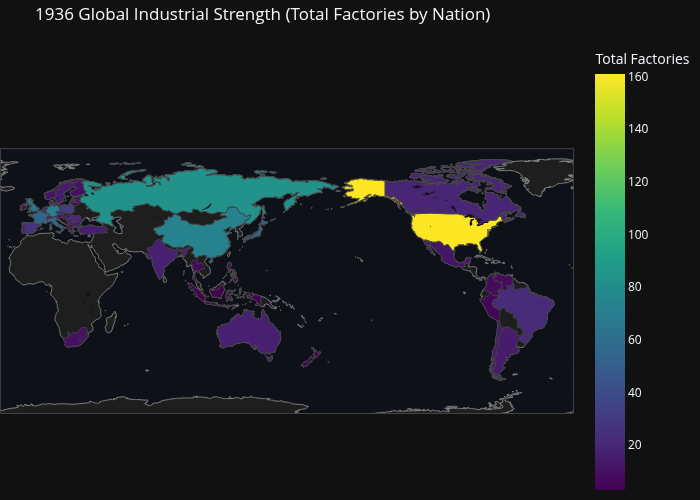

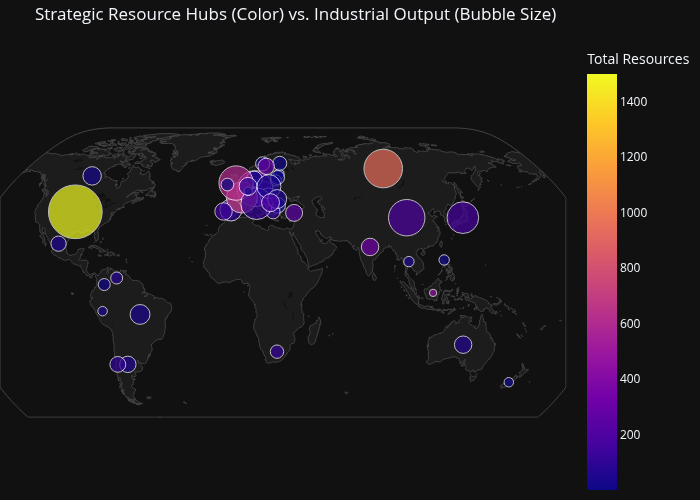

In [ ]:
# Using modern nation boundaries
TAG_TO_ISO = {
    # Major Powers
    "GER": "DEU",  # Germany
    "ENG": "GBR",  # United Kingdom
    "SOV": "RUS",  # Soviet Union
    "USA": "USA",  # United States
    "JAP": "JPN",  # Japan
    "ITA": "ITA",  # Italy
    "FRA": "FRA",  # France
    
    # China & Chinese Warlords (Mapped to CHN for ISO global boundaries)
    "CHI": "CHN",  # Republic of China
    "PRC": "CHN",  # People's Republic of China
    "MAN": "CHN",  # Manchukuo
    "MEN": "CHN",  # Mengkukuo
    "SHX": "CHN",  # Shanxi
    "XSM": "CHN",  # Xibei San Ma
    "GXC": "CHN",  # Guangxi Clique
    "YUN": "CHN",  # Yunnan
    "SIK": "CHN",  # Sinkiang
    
    # British Empire & Commonwealth
    "RAJ": "IND",  # British Raj (India)
    "AST": "AUS",  # Australia
    "CAN": "CAN",  # Canada
    "NZL": "NZL",  # New Zealand
    "SAF": "ZAF",  # South Africa
    
    # Europe
    "HOL": "NLD",  # Netherlands
    "BEL": "BEL",  # Belgium
    "LUX": "LUX",  # Luxembourg
    "POL": "POL",  # Poland
    "CZE": "CZE",  # Czechoslovakia
    "AUS": "AUT",  # Austria
    "HUN": "HUN",  # Hungary
    "ROM": "ROU",  # Romania
    "YUG": "SRB",  # Yugoslavia (Mapped to Serbia region for standard ISO)
    "BUL": "BGR",  # Bulgaria
    "GRE": "GRC",  # Greece
    "ALB": "ALB",  # Albania
    "TUR": "TUR",  # Turkey
    "SWE": "SWE",  # Sweden
    "NOR": "NOR",  # Norway
    "FIN": "FIN",  # Finland
    "DEN": "DNK",  # Denmark
    "POR": "PRT",  # Portugal
    "SPA": "ESP",  # Nationalist Spain
    "SPR": "ESP",  # Republican Spain
    "SWI": "CHE",  # Switzerland
    "IRE": "IRL",  # Ireland",
    "LAT": "LVA",  # Latvia
    "LIT": "LTU",  # Lithuania
    "EST": "EST",  # Estonia
    
    # Asia & Americas
    "SIA": "THA",  # Siam (Thailand)
    "PHI": "PHL",  # Philippines
    "INS": "IDN",  # Dutch East Indies (Indonesia)
    "MEX": "MEX",  # Mexico
    "BRA": "BRA",  # Brazil
    "ARG": "ARG",  # Argentina
    "CHL": "CHL",  # Chile
    "COL": "COL",  # Colombia
    "PER": "PER",  # Peru
    "VEN": "VEN"   # Venezuela
}

# 2. Extract Data from SQLite Database
query_map = """
SELECT 
    c.country_name,
    c.country_tag,
    COUNT(s.state_id) AS total_states,
    SUM(s.population) AS total_population,
    SUM(s.victory_points) AS total_vps,
    SUM(s.civilian_factories) AS total_civs,
    SUM(s.military_factories) AS total_mils,
    SUM(s.naval_factories) AS total_navals,
    SUM(s.total_factories) AS total_factories,
    SUM(s.base_oil) AS total_oil,
    SUM(s.base_aluminum) AS total_aluminum,
    SUM(s.base_rubber) AS total_rubber,
    SUM(s.base_tungsten) AS total_tungsten,
    SUM(s.base_steel) AS total_steel,
    SUM(s.base_chromium) AS total_chromium,
    SUM(s.total_base_resources) AS aggregate_resources
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_factories DESC;
"""

df_country_raw = pd.read_sql(query_map, engine)

# 3. Apply Tag-to-ISO Conversion
df_country_raw["iso_code"] = df_country_raw["country_tag"].map(TAG_TO_ISO)

# 4. Aggregate by ISO Code (Combines shared modern ISO territories like CHI + PRC + Warlords -> CHN)
df_map = df_country_raw.dropna(subset=["iso_code"]).groupby("iso_code", as_index=False).agg({
    "country_name": "first",
    "total_states": "sum",
    "total_population": "sum",
    "total_vps": "sum",
    "total_civs": "sum",
    "total_mils": "sum",
    "total_navals": "sum",
    "total_factories": "sum",
    "total_oil": "sum",
    "total_aluminum": "sum",
    "total_rubber": "sum",
    "total_tungsten": "sum",
    "total_steel": "sum",
    "total_chromium": "sum",
    "aggregate_resources": "sum"
})


# ---------------------------------------------------------
# MAP 1: Global Factory Capacity Choropleth (Shaded Border Map)
# ---------------------------------------------------------
fig_choropleth = px.choropleth(
    df_map,
    locations="iso_code",
    color="total_factories",
    hover_name="country_name",
    hover_data={
        "iso_code": False,
        "total_factories": ":,",
        "total_civs": ":,",
        "total_mils": ":,",
        "total_navals": ":,",
        "aggregate_resources": ":,"
    },
    color_continuous_scale="Viridis",
    title="1936 Global Industrial Strength (Total Factories by Nation)",
    labels={
        "total_factories": "Total Factories",
        "total_civs": "Civilian Factories",
        "total_mils": "Military Factories",
        "total_navals": "Naval Dockyards",
        "aggregate_resources": "Total Strategic Resources"
    },
    template="plotly_dark"
)

fig_choropleth.update_geos(
    showcoastlines=True, 
    coastlinecolor="Gray", 
    showland=True, 
    landcolor="#1e1e1e",
    showocean=True,
    oceancolor="#0e1117"
)

fig_choropleth.update_layout(margin={"r":0,"t":40,"l":0,"b":0})
fig_choropleth.show()


# ---------------------------------------------------------
# MAP 2: Strategic Resources vs Industrial Capacity (Bubble Geo Map)
# ---------------------------------------------------------
fig_geo_bubble = px.scatter_geo(
    df_map,
    locations="iso_code",
    size="total_factories",
    color="aggregate_resources",
    hover_name="country_name",
    hover_data={
        "iso_code": False,
        "total_factories": ":,",
        "aggregate_resources": ":,",
        "total_oil": ":,",
        "total_steel": ":,",
        "total_rubber": ":,"
    },
    size_max=38,
    color_continuous_scale="Plasma",
    title="Strategic Resource Hubs (Color) vs. Industrial Output (Bubble Size)",
    labels={
        "total_factories": "Total Factories",
        "aggregate_resources": "Total Resources",
        "total_oil": "Oil",
        "total_steel": "Steel",
        "total_rubber": "Rubber"
    },
    template="plotly_dark"
)

fig_geo_bubble.update_geos(
    projection_type="natural earth",
    showcoastlines=True,
    coastlinecolor="#444444",
    showland=True,
    landcolor="#1c1c1c"
)

fig_geo_bubble.update_layout(margin={"r":0,"t":40,"l":0,"b":0})
fig_geo_bubble.show()